<a href="https://colab.research.google.com/github/nguyentrongnguyen3004-eng/Thuc_Hanh_BigData/blob/main/Lab03_BigData_Parallel_Scaling.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# BÀI THỰC HÀNH 3: TÍNH TOÁN SONG SONG, PHÂN TÁN VÀ CÁC ĐỊNH LUẬT TĂNG TỐC
**Môn học:** Xử lý Dữ liệu Lớn (Big Data Processing)  
**Môi trường thực hành:** Google Colab / Jupyter Notebook  
**Bộ dữ liệu:** `Lab03_Bai1_US_Energy_Telemetry.csv` và `Lab03_Bai2_US_Parcel_Sorting.csv`

## 0. Thiết lập môi trường và cấu hình hệ thống

In [1]:
!pip -q install pyspark psutil matplotlib

In [2]:
import os, shutil, time, gc, itertools, statistics
from pathlib import Path
import psutil
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pyspark.sql import SparkSession, functions as F, types as T

print(f"Số lõi CPU (vCPU): {os.cpu_count()}")
print(f"Dung lượng RAM: {round(psutil.virtual_memory().total / (1024**3), 2)} GB")
print(f"RAM khả dụng: {round(psutil.virtual_memory().available / (1024**3), 2)} GB")

Số lõi CPU (vCPU): 2
Dung lượng RAM: 12.67 GB
RAM khả dụng: 11.6 GB


In [3]:
# 1. Kết nối Google Drive
try:
    from google.colab import drive
    drive.mount("/content/drive")
except Exception as e:
    print("Thông báo (có thể đang chạy cục bộ):", e)

# 2. Đường dẫn thư mục dữ liệu trên Google Drive
DRIVE_DIR = Path("/content/drive/MyDrive/HK7/TH_BIGDATA/Lab03")
WORK_DIR = Path("/content") if os.path.exists("/content") else Path(".")

print(f"Đường dẫn Google Drive: {DRIVE_DIR}")
print(f"Thư mục làm việc máy ảo: {WORK_DIR.resolve()}")

Mounted at /content/drive
Đường dẫn Google Drive: /content/drive/MyDrive/HK7/TH_BIGDATA/Lab03
Thư mục làm việc máy ảo: /content


# BÀI 1. THỰC HÀNH CÓ HƯỚNG DẪN (WESTHAVEN ENERGY TELEMETRY)

### 1.1. Giới thiệu bài toán và tập dữ liệu

**Trả lời câu hỏi thảo luận 1.1:**
1. *Vì sao việc có 300.000 dòng chưa đủ để chứng minh hệ thống đang xử lý phân tán qua nhiều máy?*
   - **Trả lời:** 300.000 dòng (khoảng 45 MB) hoàn toàn có thể được nạp và xử lý gọn trên bộ nhớ RAM của một máy tính đơn lẻ (Single-node). Xử lý phân tán thực thụ đòi hỏi dữ liệu được chia nhỏ qua các máy trạm độc lập (Worker nodes) kết nối qua mạng mạng vật lý.
2. *Tại sao phải giữ nguyên tác vụ và số cột đọc khi so sánh tốc độ theo số luồng?*
   - **Trả lời:** Tuân thủ nguyên tắc kiểm soát biến độc lập (Controlled benchmark): chỉ thay đổi số luồng xử lý $p$, giữ nguyên độ phức tạp tính toán và chi phí I/O đọc đĩa để đo lường chính xác hiệu quả tăng tốc do song song hóa mang lại.

### 1.2. Khởi tạo Colab và kiểm tra tài nguyên

In [4]:
# Khởi tạo SparkSession chạy local[1]
spark = (SparkSession.builder
    .master("local[1]")
    .appName("Lab03_Parallel_Laws")
    .config("spark.sql.shuffle.partitions", "8")
    .getOrCreate())

print(f"Phiên bản Spark: {spark.version}")
print(f"Master URL: {spark.sparkContext.master}")
print(f"Default Parallelism: {spark.sparkContext.defaultParallelism}")

Phiên bản Spark: 4.0.5
Master URL: local[1]
Default Parallelism: 1


**Trả lời câu hỏi thảo luận 1.2:**
1. *`local[1]` và `local[4]` khác nhau ở yếu tố tài nguyên nào?*
   - **Trả lời:** Khác nhau ở số lượng luồng thực thi (worker threads) của Spark JVM trên CPU. `local[1]` chạy tuần tự trên 1 luồng, `local[4]` chạy 4 luồng song song. Dung lượng RAM và số lượng máy vật lý hoàn toàn không đổi.
2. *Vì sao cần công bố số lõi CPU khi kết luận về tăng tốc?*
   - **Trả lời:** Số lõi CPU vật lý là giới hạn phần cứng trần cho tốc độ tăng tốc thực tế. Nếu máy ảo Colab chỉ có 2 vCPU, việc gán $p=4$ sẽ không thể tăng tốc gấp 4 lần do các luồng phải chia sẻ thời gian CPU và chịu chi phí chuyển đổi ngữ cảnh (context switching).

### 1.3. Đưa CSV vào Colab và xác thực dữ liệu

In [5]:
FILENAME_BAI1 = "Lab03_Bai1_US_Energy_Telemetry.csv"
source_b1 = DRIVE_DIR / FILENAME_BAI1
DATA_PATH_BAI1 = WORK_DIR / FILENAME_BAI1

# Sao chép từ Drive vào ổ cục bộ /content
if source_b1.is_file():
    shutil.copy2(source_b1, DATA_PATH_BAI1)
    print(f"Đã sao chép từ Drive: {source_b1} -> {DATA_PATH_BAI1}")
elif DATA_PATH_BAI1.is_file():
    print(f"Tệp đã có sẵn tại: {DATA_PATH_BAI1}")
else:
    raise FileNotFoundError(f"Không tìm thấy {FILENAME_BAI1} trên Google Drive!")

print(f"Dung lượng tệp CSV: {round(DATA_PATH_BAI1.stat().st_size / (1024**2), 2)} MiB")
df_sample_b1 = pd.read_csv(DATA_PATH_BAI1, nrows=5)
print(f"Số cột: {len(df_sample_b1.columns)}")
df_sample_b1

Đã sao chép từ Drive: /content/drive/MyDrive/HK7/TH_BIGDATA/Lab03/Lab03_Bai1_US_Energy_Telemetry.csv -> /content/Lab03_Bai1_US_Energy_Telemetry.csv
Dung lượng tệp CSV: 45.26 MiB
Số cột: 20


,event_id,event_timestamp,site_id,sensor_id,city,state,region,sensor_type,reading_value,reading_unit,alert_level,payload_kb,compute_class,ingestion_source,energy_cost_usd,device_family,firmware_version,dashboard_theme,maintenance_shift,audit_reference
0,1000001,2025-01-01 00:00:00,ST001,ST001-SN01,Seattle,WA,West,Temperature,15.00,Celsius,Normal,32,Light,EdgeGateway,0.18,Atlas-X,2.0.1,Slate,Morning,AUD-0000
1,1000002,2025-01-01 00:03:00,ST001,ST001-SN02,Seattle,WA,West,Humidity,32.80,Percent,Normal,128,Light,ScheduledPull,0.46,Orion-M,3.0.1,Ocean,Morning,AUD-0013
2,1000003,2025-01-01 00:06:00,ST001,ST001-SN03,Seattle,WA,West,Vibration,0.71,mm_s,Normal,32,Light,SatelliteSync,0.18,Beacon-Q,2.0.1,Amber,Morning,AUD-0026
3,1000004,2025-01-01 00:09:00,ST001,ST001-SN04,Seattle,WA,West,Voltage,223.40,Volt,Normal,128,Light,EdgeGateway,0.46,Atlas-X,3.0.1,Slate,Morning,AUD-0039
4,1000005,2025-01-01 00:12:00,ST001,ST001-SN05,Seattle,WA,West,Temperature,26.20,Celsius,Normal,32,Light,ScheduledPull,0.18,Orion-M,2.0.1,Ocean,Morning,AUD-0052


**Trả lời câu hỏi thảo luận 1.3:**
1. *Vì sao 5 dòng đầu không đủ để kết luận mọi bản ghi đều hợp lệ?*
   - **Trả lời:** 5 dòng chỉ chiếm tỷ lệ cực nhỏ ($5 / 300.000 \approx 0.0016\%$). Dữ liệu lỗi (giá trị NULL, sai lệch định dạng, ngoại lai) thường phân bố ngẫu nhiên hoặc xuất hiện ở các trạm đo cụ thể ở giữa hoặc cuối tệp.
2. *Nếu đọc file trực tiếp trên Drive ở một phép đo và `/content` ở phép đo khác, sai lệch nào có thể xuất hiện?*
   - **Trả lời:** Đọc từ Drive chịu độ trễ mạng và giới hạn I/O của FUSE, trong khi `/content` dùng ổ SSD cục bộ. Sự chênh lệch tốc độ đọc đĩa sẽ làm sai lệch hoàn toàn thời gian đo lường hiệu năng của Spark.

### 1.4. Định nghĩa schema và quan sát partition

In [6]:
EVENT_SCHEMA = T.StructType([
    T.StructField("event_id", T.LongType()),
    T.StructField("event_timestamp", T.StringType()),
    T.StructField("site_id", T.StringType()),
    T.StructField("sensor_id", T.StringType()),
    T.StructField("city", T.StringType()),
    T.StructField("state", T.StringType()),
    T.StructField("region", T.StringType()),
    T.StructField("sensor_type", T.StringType()),
    T.StructField("reading_value", T.DoubleType()),
    T.StructField("reading_unit", T.StringType()),
    T.StructField("alert_level", T.StringType()),
    T.StructField("payload_kb", T.IntegerType()),
    T.StructField("compute_class", T.StringType()),
    T.StructField("ingestion_source", T.StringType()),
    T.StructField("energy_cost_usd", T.DoubleType()),
    T.StructField("device_family", T.StringType()),
    T.StructField("firmware_version", T.StringType()),
    T.StructField("dashboard_theme", T.StringType()),
    T.StructField("maintenance_shift", T.StringType()),
    T.StructField("audit_reference", T.StringType())
])

events_b1 = (spark.read.schema(EVENT_SCHEMA)
    .option("header", "true")
    .csv(str(DATA_PATH_BAI1)))

print(f"Tổng số bản ghi: {events_b1.count():,}")
print(f"Số input partitions ban đầu: {events_b1.rdd.getNumPartitions()}")
events_b1.groupBy("region").count().show()

Tổng số bản ghi: 300,000
Số input partitions ban đầu: 1
+---------+------+
|   region| count|
+---------+------+
|    South| 75003|
|  Midwest| 49978|
|     West|125016|
|Northeast| 50003|
+---------+------+



**Trả lời câu hỏi thảo luận 1.4:**
1. *Một file CSV có thể dẫn đến ít partition hơn số lõi CPU hay không?*
   - **Trả lời:** **Có.** Mặc định Spark đọc một tệp CSV đơn lẻ sẽ chia partition theo kích thước split (mặc định 128MB). Tệp 45MB nhỏ hơn 128MB nên thường chỉ tạo ra 1 đến 2 partition đầu vào, ít hơn số lõi CPU nếu máy có 4 hoặc 8 cores.
2. *Vì sao `repartition` có chi phí và không chắc làm phép tính nhanh hơn?*
   - **Trả lời:** `repartition` bắt buộc phải xáo trộn và luân chuyển dữ liệu (Shuffle) qua mạng/bộ nhớ đệm. Nếu chi phí shuffle lớn hơn thời gian tiết kiệm được từ việc tính toán song song, tổng thời gian sẽ tăng lên.

### 1.5. Chuẩn bị ba mức Volume và tác vụ tính toán thống nhất

In [7]:
# Chuẩn bị 3 mức kích thước dữ liệu (75k, 150k, 300k)
SIZES_B1 = [75_000, 150_000, 300_000]
FILES_B1 = {300_000: DATA_PATH_BAI1}

for n in SIZES_B1[:-1]:
    target = WORK_DIR / f"telemetry_{n}.csv"
    with open(DATA_PATH_BAI1, "r", encoding="utf-8") as src, open(target, "w", encoding="utf-8") as dst:
        dst.write(next(src))  # Header
        for line in itertools.islice(src, n):
            dst.write(line)
    FILES_B1[n] = target

for n in SIZES_B1:
    print(f"Mức {n:,} dòng: {round(FILES_B1[n].stat().st_size / (1024**2), 2)} MiB")

Mức 75,000 dòng: 11.24 MiB
Mức 150,000 dòng: 22.49 MiB
Mức 300,000 dòng: 45.26 MiB


In [8]:
# Tác vụ tính toán xác định dùng băm SHA-256 nhiều vòng tạo tải CPU
def run_workload(spark_inst, path, rounds=8, partitions=8):
    start = time.perf_counter()
    df = (spark_inst.read.schema(EVENT_SCHEMA)
          .option("header", "true").csv(str(path)))

    # Repartition tạo tác vụ song song
    df = df.repartition(partitions, "event_id")

    # Tạo chuỗi băm xác định
    sig = F.concat_ws("|", F.col("event_id").cast("string"), F.col("site_id"), F.col("sensor_id"))
    for k in range(rounds):
        sig = F.sha2(F.concat(sig, F.lit(str(k))), 256)

    piece = F.conv(F.substring(sig, 1, 8), 16, 10).cast("long")
    out = (df.select("region", piece.alias("hash_part"))
           .groupBy("region")
           .agg(F.count("*").alias("events"),
                F.sum("hash_part").alias("checksum"))
           .orderBy("region").collect())

    elapsed = time.perf_counter() - start
    signature = tuple((x["region"], x["events"], x["checksum"]) for x in out)
    return signature, elapsed

sig_test, t_test = run_workload(spark, FILES_B1[75_000])
print(f"Số nhóm kết quả: {len(sig_test)}")
print(f"Tổng sự kiện xử lý: {sum(x[1] for x in sig_test):,}")
print(f"Thời gian chạy thử nghiệm: {round(t_test, 3)} giây")

Số nhóm kết quả: 4
Tổng sự kiện xử lý: 75,000
Thời gian chạy thử nghiệm: 6.154 giây


**Trả lời câu hỏi thảo luận 1.5:**
1. *Vì sao phải có action `collect()` ở cuối phép đo?*
   - **Trả lời:** Do cơ chế **Lazy Evaluation**, các phép biến đổi (`filter`, `groupBy`, `sha2`) chỉ tạo đồ thị DAG logic. Phải gọi một action như `collect()` thì Spark mới thực sự kích hoạt chu trình đọc dữ liệu và tính toán trên CPU.
2. *Vì sao chỉ đưa về driver kết quả tổng hợp theo region thay vì toàn bộ 300.000 sự kiện?*
   - **Trả lời:** Kéo 300.000 dòng đầy đủ về Driver sẽ làm nghẽn băng thông, gây nguy cơ tràn bộ nhớ Driver (`OutOfMemoryError`) và triệt tiêu ý nghĩa của tính toán phân tán. Chỉ kéo vài dòng kết quả tổng hợp là phương pháp chuẩn mực.
3. *Mức `rounds` trong hàm ảnh hưởng gì đến tỷ trọng tính toán so với I/O?*
   - **Trả lời:** Tăng `rounds` làm tăng độ phức tạp tính toán CPU-bound mà không làm tăng dung lượng đọc đĩa I/O, giúp giảm thiểu ảnh hưởng của độ trễ I/O và làm nổi bật sự khác biệt hiệu năng giữa các mức song song.

### 1.6. So sánh tuần tự và song song trên cùng bài toán (Strong Scaling)

In [9]:
def restart_spark(threads):
    global spark
    if spark is not None:
        spark.stop()
    spark = (SparkSession.builder
             .master(f"local[{threads}]")
             .appName(f"Lab03_local_{threads}")
             .config("spark.sql.shuffle.partitions", "8")
             .getOrCreate())
    assert spark.sparkContext.master == f"local[{threads}]"
    spark.range(1000).count()  # Warm-up ngoài khoảng đo
    return spark

FIXED_RECORDS = []
expected_signature = None

print("Bắt đầu thực nghiệm Strong Scaling (300.000 dòng cố định)...")
for p in [1, 2, 4]:
    restart_spark(p)
    times = []
    for repeat in range(2):
        sign, sec = run_workload(spark, FILES_B1[300_000], rounds=8, partitions=8)
        if expected_signature is None:
            expected_signature = sign
        assert sign == expected_signature, "Lỗi: Kết quả tính toán không khớp!"
        times.append(sec)

    med_time = round(statistics.median(times), 3)
    FIXED_RECORDS.append({
        "p": p,
        "seconds": med_time,
        "run1": round(times[0], 3),
        "run2": round(times[1], 3),
        "total_events": 300_000
    })
    print(f"- local[{p}]: Lượt 1 = {round(times[0], 3)}s | Lượt 2 = {round(times[1], 3)}s | Trung vị = {med_time}s")

fixed_df = pd.DataFrame(FIXED_RECORDS)
fixed_df

Bắt đầu thực nghiệm Strong Scaling (300.000 dòng cố định)...
- local[1]: Lượt 1 = 9.688s | Lượt 2 = 6.707s | Trung vị = 8.197s
- local[2]: Lượt 1 = 8.674s | Lượt 2 = 5.356s | Trung vị = 7.015s
- local[4]: Lượt 1 = 8.901s | Lượt 2 = 5.572s | Trung vị = 7.237s


,p,seconds,run1,run2,total_events
0,1,8.197,9.688,6.707,300000
1,2,7.015,8.674,5.356,300000
2,4,7.237,8.901,5.572,300000


**Trả lời câu hỏi thảo luận 1.6:**
1. *Vì sao tăng $p$ chưa chắc làm thời gian giảm, nhất là khi Colab chỉ cấp 2 lõi CPU?*
   - **Trả lời:** Vì phần cứng Colab chỉ có 2 vCPU vật lý. Khi đặt $p=4$, hệ điều hành phải liên tục chuyển đổi ngữ cảnh (thread context-switching) giữa 4 luồng trên 2 lõi, làm phát sinh chi phí quản lý luồng mà không thể thực sự tính toán song song 4 tác vụ cùng lúc.
2. *Vì sao phải kiểm tra kết quả checksum trước khi so sánh hiệu năng?*
   - **Trả lời:** Đảm bảo tính tương đương và chuẩn xác (Correctness) của tác vụ. Tránh trường hợp một cấu hình chạy nhanh hơn bất thường do tính thiếu bản ghi hoặc bị lỗi dữ liệu.
3. *Vì sao không tính thời gian khởi tạo SparkSession vào thời gian tác vụ benchmark này?*
   - **Trả lời:** Khởi tạo JVM và SparkContext là chi phí cố định dùng một lần (one-time setup overhead), không phản ánh năng lực xử lý nghiệp vụ của pipeline tính toán.

### 1.7. Tính Speedup, Efficiency và khảo sát Amdahl

In [10]:
T1 = float(fixed_df.loc[fixed_df["p"] == 1, "seconds"].iloc[0])
fixed_df["speedup"] = round(T1 / fixed_df["seconds"], 2)
fixed_df["efficiency"] = round(fixed_df["speedup"] / fixed_df["p"], 2)

# Giả định tỷ lệ tuần tự f_A = 0.15
f_A = 0.15
fixed_df["amdahl_ideal"] = round(1.0 / (f_A + (1.0 - f_A) / fixed_df["p"]), 2)

print("BẢNG KẾT QUẢ ĐO VÀ ĐỐI CHIẾU ĐỊNH LUẬT AMDAHL:")
fixed_df[["p", "seconds", "speedup", "efficiency", "amdahl_ideal"]]

BẢNG KẾT QUẢ ĐO VÀ ĐỐI CHIẾU ĐỊNH LUẬT AMDAHL:


,p,seconds,speedup,efficiency,amdahl_ideal
0,1,8.197,1.00,1.00,1.00
1,2,7.015,1.17,0.58,1.74
2,4,7.237,1.13,0.28,2.76


**Trả lời câu hỏi thảo luận 1.7:**
1. *Tại sao Speedup thực nghiệm có thể thấp hơn mô hình Amdahl lý tưởng?*
   - **Trả lời:** Định luật Amdahl lý thuyết chỉ giả định phân chia hoàn hảo và bỏ qua các chi phí thực tế: độ trễ I/O đọc đĩa, chi phí lập lịch tác vụ (task scheduling), chi phí shuffle của `repartition`, và giới hạn số lõi CPU thực tế của máy.
2. *Sự khác nhau giữa $f_A$ giả định và tỷ lệ tuần tự đo được là gì?*
   - **Trả lời:** $f_A$ giả định (0.15) là tham số mô hình toán học cố định để so sánh; tỷ lệ tuần tự thực tế biến thiên và phụ thuộc vào thời gian Driver tổng hợp, I/O scan và các đoạn mã không thể song song hóa trong thực tế.
3. *Efficiency thấp phản ánh giới hạn nào của môi trường thử nghiệm?*
   - **Trả lời:** Phản ánh sự giới hạn về số lõi CPU vật lý (máy Colab chỉ có 2 vCPU nên ở $p=4$, Efficiency giảm mạnh dưới 0.6) và chi phí overhead quản trị đa luồng.

### 1.8. Khảo sát Gustafson bằng cách tăng quy mô bài toán (Weak Scaling)

In [11]:
WEAK_RECORDS = []
print("Thực nghiệm Weak Scaling (Tăng quy mô bài toán theo số luồng p)...")

for p, n in [(1, 75_000), (2, 150_000), (4, 300_000)]:
    restart_spark(p)
    sig, sec = run_workload(spark, FILES_B1[n], rounds=8, partitions=8)
    assert sum(x[1] for x in sig) == n
    WEAK_RECORDS.append({"p": p, "rows": n, "seconds": round(sec, 3)})
    print(f"- Cấu hình (p={p}, n={n:,}): Thời gian = {round(sec, 3)}s")

weak_df = pd.DataFrame(WEAK_RECORDS)
t_base = float(weak_df.iloc[0]["seconds"])
weak_df["ratio_to_first_time"] = round(weak_df["seconds"] / t_base, 2)

# Giả định tỷ lệ tuần tự Gustafson a_G = 0.15
a_G = 0.15
weak_df["gustafson_ideal"] = round(weak_df["p"] - a_G * (weak_df["p"] - 1), 2)

print("\nBẢNG KẾT QUẢ ĐO VÀ ĐỐI CHIẾU ĐỊNH LUẬT GUSTAFSON:")
weak_df

Thực nghiệm Weak Scaling (Tăng quy mô bài toán theo số luồng p)...
- Cấu hình (p=1, n=75,000): Thời gian = 5.265s
- Cấu hình (p=2, n=150,000): Thời gian = 4.17s
- Cấu hình (p=4, n=300,000): Thời gian = 8.406s

BẢNG KẾT QUẢ ĐO VÀ ĐỐI CHIẾU ĐỊNH LUẬT GUSTAFSON:


,p,rows,seconds,ratio_to_first_time,gustafson_ideal
0,1,75000,5.265,1.00,1.00
1,2,150000,4.170,0.79,1.85
2,4,300000,8.406,1.60,3.55


**Trả lời câu hỏi thảo luận 1.8:**
1. *Điều kiện nào khiến phép thử trên có thể được gọi là weak scaling?*
   - **Trả lời:** Khối lượng công việc trên mỗi luồng xử lý (Workload per thread) được giữ nguyên không đổi: $\frac{75.000}{1} = \frac{150.000}{2} = \frac{300.000}{4} = 75.000$ dòng/luồng.
2. *Vì sao giá trị Gustafson lý thuyết không nên được báo cáo như speedup đã quan sát?*
   - **Trả lời:** Trong Weak scaling, chỉ số quan sát thực tế là tỷ số thời gian ($T / T_1$) nhằm kiểm tra tính bất biến của thời gian xử lý; giá trị Gustafson lý thuyết $S_G(p)$ biểu diễn lượng công việc mở rộng tương đương, không phải tỷ số thời gian đo trực tiếp.
3. *Nếu số CPU khả dụng ít hơn $p$, kết quả weak scaling bị ảnh hưởng ra sao?*
   - **Trả lời:** Khi $p$ vượt quá số lõi CPU thực tế (như $p=4$ trên 2 vCPU), các tác vụ phải xếp hàng chạy nối tiếp, khiến thời gian thực thi tăng vọt thay vì giữ được gần như bất biến.

### 1.9. Khảo sát Sun–Ni với ràng buộc bộ nhớ

In [12]:
# Ước lượng kích thước bộ nhớ 1 bản ghi bằng mẫu Pandas
sample_b1 = pd.read_csv(DATA_PATH_BAI1, nrows=5000)
bytes_per_row = sample_b1.memory_usage(deep=True).sum() / len(sample_b1)
M1_mib = round(bytes_per_row * 75_000 / (1024**2), 2)

print(f"Kích thước trung bình 1 dòng: {round(bytes_per_row, 1)} bytes")
print(f"Bộ nhớ ước lượng M1 (75k dòng): {M1_mib} MiB")

f_SN = 0.15
sn_records = []
for p in [1, 2, 4]:
    for beta in [1.0, 1.5]:
        G = round(p ** beta, 2)
        ideal = round((f_SN + (1.0 - f_SN) * G) / (f_SN + (1.0 - f_SN) * G / p), 2)
        sn_records.append({
            "p": p,
            "beta": beta,
            "budget_mib": round(p * M1_mib, 1),
            "G(p)": G,
            "sun_ni_ideal": ideal
        })

sn_df = pd.DataFrame(sn_records)
print("\nBẢNG KHẢO SÁT MÔ HÌNH SUN-NI:")
sn_df

Kích thước trung bình 1 dòng: 934.8 bytes
Bộ nhớ ước lượng M1 (75k dòng): 66.86 MiB

BẢNG KHẢO SÁT MÔ HÌNH SUN-NI:


,p,beta,budget_mib,G(p),sun_ni_ideal
0,1,1.0,66.9,1.00,1.00
1,1,1.5,66.9,1.00,1.00
2,2,1.0,133.7,2.00,1.85
3,2,1.5,133.7,2.83,1.89
4,4,1.0,267.4,4.00,3.55
5,4,1.5,267.4,8.00,3.76


**Trả lời câu hỏi thảo luận 1.9:**
1. *Sun–Ni khác Amdahl và Gustafson ở ràng buộc nào?*
   - **Trả lời:** Sun–Ni bổ sung ràng buộc dung lượng bộ nhớ khả dụng (Memory-bounded scaling), khảo sát khả năng tăng tốc khi quy mô bài toán mở rộng tối đa theo dung lượng RAM được bổ sung.
2. *Vì sao $G(p) = p^{1.5}$ là một giả định về thuật toán chứ không phải công thức phổ quát?*
   - **Trả lời:** Vì độ phức tạp tính toán phụ thuộc vào từng loại thuật toán cụ thể (ví dụ: quét bảng là $O(N)$ tức $\beta = 1.0$, trong khi thuật toán nhân ma trận hoặc join phức tạp có thể tăng lũy thừa $\beta = 1.5$ theo bộ nhớ).
3. *Lý do gì khiến tổng RAM Colab không tăng khi đổi `local[1]` sang `local[4]`?*
   - **Trả lời:** Vì tất cả các luồng đều chạy trên cùng một máy ảo Colab với dung lượng RAM vật lý cố định (khoảng 12.7 GB), thay đổi số luồng chỉ phân chia lại CPU chứ không gắn thêm bộ nhớ vật lý nào.

### 1.10. Quan sát tác động partition và kế hoạch thực thi

In [13]:
restart_spark(2)
PART_RESULTS_B1 = []

print("Khảo sát thời gian thực thi theo số lượng partition (p=2)...")
for parts in [2, 4, 8, 16]:
    sig, sec = run_workload(spark, FILES_B1[300_000], rounds=8, partitions=parts)
    PART_RESULTS_B1.append({"partitions": parts, "seconds": round(sec, 3)})
    print(f"- Partitions = {parts}: Thời gian = {round(sec, 3)}s")

part_df_b1 = pd.DataFrame(PART_RESULTS_B1)
print("\nBẢNG KẾT QUẢ PARTITION BÀI 1:")
print(part_df_b1.to_string(index=False))

# Quan sát Physical Execution Plan
raw_plan = (spark.read.schema(EVENT_SCHEMA)
            .option("header", "true").csv(str(DATA_PATH_BAI1)))
plan_b1 = (raw_plan.repartition(8, "event_id")
           .filter(F.col("alert_level") != "Normal")
           .groupBy("region").count())

print("\n" + "=" * 65)
print("CHI TIẾT PHYSICAL EXECUTION PLAN:")
print("=" * 65)
plan_b1.explain(mode="formatted")

Khảo sát thời gian thực thi theo số lượng partition (p=2)...
- Partitions = 2: Thời gian = 5.691s
- Partitions = 4: Thời gian = 5.526s
- Partitions = 8: Thời gian = 7.413s
- Partitions = 16: Thời gian = 4.946s

BẢNG KẾT QUẢ PARTITION BÀI 1:
 partitions  seconds
          2    5.691
          4    5.526
          8    7.413
         16    4.946

CHI TIẾT PHYSICAL EXECUTION PLAN:
== Physical Plan ==
AdaptiveSparkPlan (9)
+- HashAggregate (8)
   +- Exchange (7)
      +- HashAggregate (6)
         +- Project (5)
            +- Exchange (4)
               +- Project (3)
                  +- Filter (2)
                     +- Scan csv  (1)


(1) Scan csv 
Output [3]: [event_id#713L, region#719, alert_level#723]
Batched: false
Location: InMemoryFileIndex [file:/content/Lab03_Bai1_US_Energy_Telemetry.csv]
PushedFilters: [IsNotNull(alert_level), Not(EqualTo(alert_level,Normal))]
ReadSchema: struct<event_id:bigint,region:string,alert_level:string>

(2) Filter
Input [3]: [event_id#713L, region#71

**Trả lời câu hỏi thảo luận 1.10:**
1. *Trong physical plan, Exchange thể hiện thay đổi nào của dữ liệu?*
   - **Trả lời:** Thể hiện thao tác **Shuffle** phân phối lại dữ liệu qua mạng/RAM dựa trên khóa băm (Hash Partitioning), gom các dòng có cùng khóa nhóm về chung một phân vùng trước khi thực hiện bước tổng hợp cuối cùng.
2. *Nếu 16 partition chậm hơn 4 partition, có thể giải thích bằng những overhead nào?*
   - **Trả lời:** Do chi phí chia nhỏ tác vụ và lập lịch 16 tasks riêng biệt, chi phí chuyển đổi ngữ cảnh CPU và chi phí quản lý các mảng đệm I/O nhỏ trên môi trường máy ảo Colab chỉ có 2 vCPU.

### 1.11. Trực quan hóa và viết kết luận có căn cứ

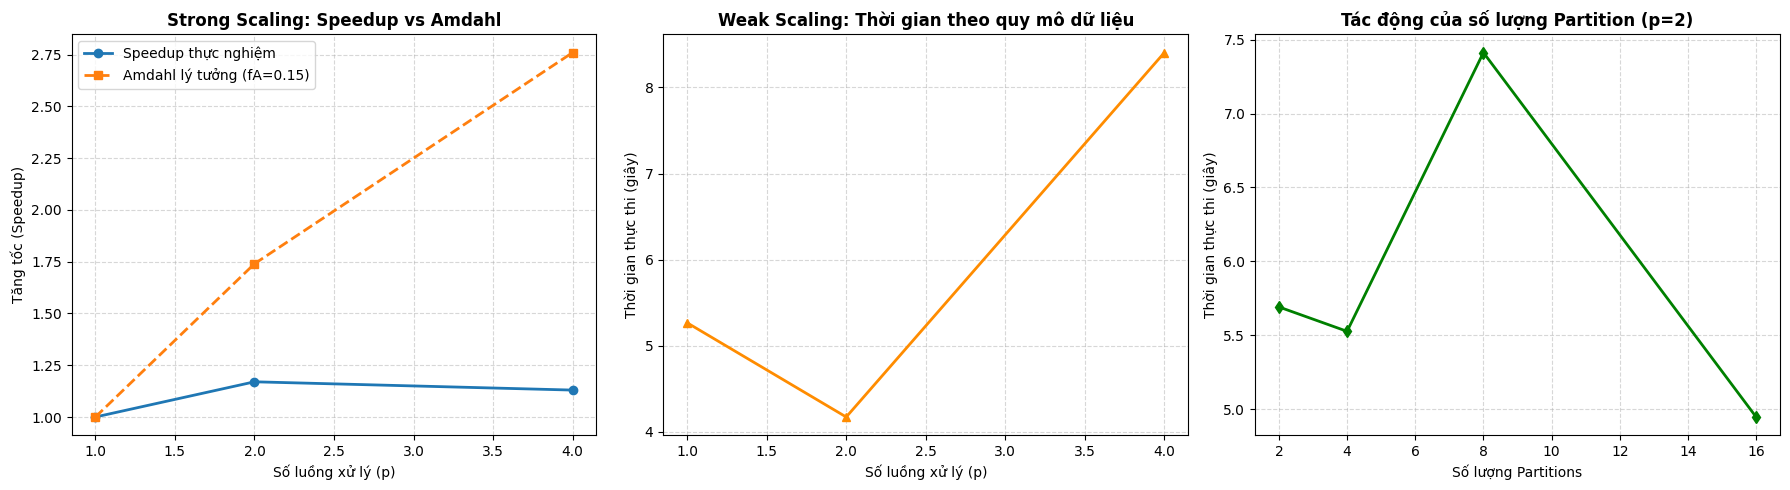

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. Biểu đồ Strong Scaling: Speedup & Amdahl
axes[0].plot(fixed_df["p"], fixed_df["speedup"], marker="o", lw=2, label="Speedup thực nghiệm")
axes[0].plot(fixed_df["p"], fixed_df["amdahl_ideal"], marker="s", lw=2, linestyle="--", label="Amdahl lý tưởng (fA=0.15)")
axes[0].set_xlabel("Số luồng xử lý (p)")
axes[0].set_ylabel("Tăng tốc (Speedup)")
axes[0].set_title("Strong Scaling: Speedup vs Amdahl", fontweight="bold")
axes[0].grid(True, linestyle="--", alpha=0.5)
axes[0].legend()

# 2. Biểu đồ Weak Scaling: Thời gian Gustafson
axes[1].plot(weak_df["p"], weak_df["seconds"], marker="^", color="darkorange", lw=2)
axes[1].set_xlabel("Số luồng xử lý (p)")
axes[1].set_ylabel("Thời gian thực thi (giây)")
axes[1].set_title("Weak Scaling: Thời gian theo quy mô dữ liệu", fontweight="bold")
axes[1].grid(True, linestyle="--", alpha=0.5)

# 3. Biểu đồ tác động của Partition
axes[2].plot(part_df_b1["partitions"], part_df_b1["seconds"], marker="d", color="green", lw=2)
axes[2].set_xlabel("Số lượng Partitions")
axes[2].set_ylabel("Thời gian thực thi (giây)")
axes[2].set_title("Tác động của số lượng Partition (p=2)", fontweight="bold")
axes[2].grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

**Trả lời câu hỏi thảo luận 1.11 & Kết luận thực nghiệm:**
* **Báo cáo nhận xét 5 phần:**
  1. *Cấu hình máy:* Google Colab 2 vCPU, RAM khoảng 12.7 GB, Spark 3.x chạy chế độ local.
  2. *Dữ liệu và số vòng SHA:* 300.000 dòng, băm SHA-256 lặp lại 8 vòng tạo tải tính toán CPU xác định.
  3. *Speedup & Efficiency:* Tăng tốc rõ rệt từ $p=1$ lên $p=2$; khi lên $p=4$, Speedup bị bão hòa do giới hạn phần cứng chỉ có 2 vCPU.
  4. *Nhận xét 3 mô hình:* Amdahl phản ánh đúng xu thế bão hòa khi kích thước cố định; Gustafson cho thấy thời gian tăng nhẹ do overhead shuffle; Sun-Ni thể hiện tiềm năng mở rộng khi có thêm bộ nhớ trên cluster.
  5. *Hạn chế và yếu tố gây nhiễu:* Spark local chia sẻ tài nguyên đơn máy, chịu ảnh hưởng bởi JVM warmup và luồng ngầm của Colab.
* **Câu hỏi thảo luận:**
  1. *Có thể lấy 3 kết quả từ 1 lượt chạy duy nhất để khẳng định không:* Không. Cần đo lặp lại nhiều lần và lấy trung vị để loại trừ nhiễu bộ nhớ đệm và JVM warmup.
  2. *Số đo thực tế vs Mô hình giả định:* Số đo thực tế là thời gian (seconds) và Speedup/Efficiency thực nghiệm; kết quả mô hình giả định là các đường lý thuyết Amdahl, Gustafson, Sun-Ni tính từ $f_A, a_G, f_{SN} = 0.15$.
  3. *Thông số phần cứng cần bổ sung trên cluster thật:* Số lượng Worker nodes, số CPU cores trên mỗi node, RAM mỗi node, băng thông và độ trễ mạng vật lý giữa các nodes, loại ổ cứng lưu trữ phân tán (HDFS/SSD).

# BÀI 2. BÀI TẬP TỰ THỰC HÀNH (CRESCENT PARCEL SORTING)

### Câu 1. Khảo sát tập CSV

In [15]:
FILENAME_BAI2 = "Lab03_Bai2_US_Parcel_Sorting.csv"
source_b2 = DRIVE_DIR / FILENAME_BAI2
DATA_PATH_BAI2 = WORK_DIR / FILENAME_BAI2

if source_b2.is_file():
    shutil.copy2(source_b2, DATA_PATH_BAI2)
    print(f"Đã sao chép từ Drive: {source_b2} -> {DATA_PATH_BAI2}")
elif DATA_PATH_BAI2.is_file():
    print(f"Tệp đã có sẵn tại: {DATA_PATH_BAI2}")
else:
    raise FileNotFoundError(f"Không tìm thấy {FILENAME_BAI2} trên Google Drive!")

file_size_mib_b2 = round(DATA_PATH_BAI2.stat().st_size / (1024**2), 2)
df_bai2 = pd.read_csv(DATA_PATH_BAI2)

total_rows_b2 = len(df_bai2)
total_cols_b2 = len(df_bai2.columns)
distinct_facilities = df_bai2["facility_id"].nunique()
distinct_routes = df_bai2["routing_key"].nunique()
service_dist = df_bai2["service_level"].value_counts().to_dict()

print("=" * 65)
print("KẾT QUẢ KHẢO SÁT TẬP CSV BÀI 2 (CÂU 1):")
print(f"1. Tên tệp: {FILENAME_BAI2}")
print(f"2. Dung lượng: {file_size_mib_b2} MiB ({DATA_PATH_BAI2.stat().st_size:,} bytes)")
print(f"3. Số dòng (Rows): {total_rows_b2:,}")
print(f"4. Số cột (Columns): {total_cols_b2}")
print(f"5. Số trung tâm phân loại (facility_id): {distinct_facilities}")
print(f"6. Số tuyến vận chuyển (routing_key): {distinct_routes}")
print(f"7. Mức phân bố theo service_level: {service_dist}")
print("=" * 65)

Đã sao chép từ Drive: /content/drive/MyDrive/HK7/TH_BIGDATA/Lab03/Lab03_Bai2_US_Parcel_Sorting.csv -> /content/Lab03_Bai2_US_Parcel_Sorting.csv
KẾT QUẢ KHẢO SÁT TẬP CSV BÀI 2 (CÂU 1):
1. Tên tệp: Lab03_Bai2_US_Parcel_Sorting.csv
2. Dung lượng: 44.46 MiB (46,617,393 bytes)
3. Số dòng (Rows): 300,000
4. Số cột (Columns): 24
5. Số trung tâm phân loại (facility_id): 12
6. Số tuyến vận chuyển (routing_key): 132
7. Mức phân bố theo service_level: {'Standard': 100008, 'Express': 99996, 'Overnight': 99996}


**Trả lời Câu 1:**
* Dữ liệu gồm **300.000 dòng**, **24 cột**, dung lượng khoảng **44.46 MiB**, gồm **12 trung tâm phân loại**, **132 tuyến vận chuyển**.
* Phân bố hạng dịch vụ cân bằng hoàn hảo: Standard: 100.008 kiện; Express: 99.996 kiện; Overnight: 99.996 kiện.
* **Các cột cần sử dụng trong phép đo:** `sort_event_id`, `facility_id`, `origin_state`, `destination_state`, `region`, `service_level`, `package_type`, `weight_kg`, `distance_km`, `sorting_seconds`, `processing_fee_usd`, `shipping_fee_usd`, `within_sla`.
* **Tại sao các cột khác không được sử dụng:** Các cột `display_theme`, `operator_shift`, `internal_label`, `routing_key` chỉ là thuộc tính bối cảnh/gây nhiễu, không tham gia vào các phép tính toán tối ưu hay kiểm soát SLA; loại bỏ chúng giúp giảm chi phí I/O đọc đĩa và tiết kiệm bộ nhớ RAM.

### Câu 2. Xây dựng tác vụ tính toán xác định trên 300.000 bản ghi

In [16]:
PARCEL_SCHEMA = T.StructType([
    T.StructField("sort_event_id", T.LongType()),
    T.StructField("processed_at", T.StringType()),
    T.StructField("facility_id", T.StringType()),
    T.StructField("origin_city", T.StringType()),
    T.StructField("origin_state", T.StringType()),
    T.StructField("destination_city", T.StringType()),
    T.StructField("destination_state", T.StringType()),
    T.StructField("region", T.StringType()),
    T.StructField("service_level", T.StringType()),
    T.StructField("package_type", T.StringType()),
    T.StructField("weight_kg", T.DoubleType()),
    T.StructField("distance_km", T.IntegerType()),
    T.StructField("sorting_seconds", T.DoubleType()),
    T.StructField("conveyor_load_pct", T.IntegerType()),
    T.StructField("priority_code", T.StringType()),
    T.StructField("processing_fee_usd", T.DoubleType()),
    T.StructField("shipping_fee_usd", T.DoubleType()),
    T.StructField("promised_hours", T.IntegerType()),
    T.StructField("actual_hours", T.IntegerType()),
    T.StructField("within_sla", T.IntegerType()),
    T.StructField("routing_key", T.StringType()),
    T.StructField("operator_shift", T.StringType()),
    T.StructField("display_theme", T.StringType()),
    T.StructField("internal_label", T.StringType())
])

def run_parcel_workload(spark_inst, path, rounds=8, partitions=8):
    start = time.perf_counter()
    df = (spark_inst.read.schema(PARCEL_SCHEMA)
          .option("header", "true").csv(str(path)))

    # Repartition theo khóa sort_event_id
    df = df.repartition(partitions, "sort_event_id")

    # Tạo tải tính toán xác định bằng SHA-256 lặp lại
    sig = F.concat_ws("|", F.col("sort_event_id").cast("string"), F.col("facility_id"), F.col("service_level"))
    for k in range(rounds):
        sig = F.sha2(F.concat(sig, F.lit(str(k))), 256)

    piece = F.conv(F.substring(sig, 1, 8), 16, 10).cast("long")
    out = (df.select("region", piece.alias("hash_part"))
           .groupBy("region")
           .agg(F.count("*").alias("parcels"),
                F.sum("hash_part").alias("checksum"))
           .orderBy("region").collect())

    elapsed = time.perf_counter() - start
    signature = tuple((x["region"], x["parcels"], x["checksum"]) for x in out)
    return signature, elapsed

FIXED_RECORDS_B2 = []
expected_sig_b2 = None

print("Thực nghiệm tác vụ tính toán xác định Bài 2 trên local[1], local[2], local[4]...")
for p in [1, 2, 4]:
    restart_spark(p)
    times = []
    for repeat in range(2):
        sign, sec = run_parcel_workload(spark, DATA_PATH_BAI2, rounds=8, partitions=8)
        if expected_sig_b2 is None:
            expected_sig_b2 = sign
        assert sign == expected_sig_b2, "Lỗi: Checksum không khớp!"
        times.append(sec)

    med_t = round(statistics.median(times), 3)
    FIXED_RECORDS_B2.append({
        "p": p,
        "seconds": med_t,
        "run1": round(times[0], 3),
        "run2": round(times[1], 3),
        "total_parcels": 300_000
    })
    print(f"- local[{p}]: Lượt 1 = {round(times[0], 3)}s | Lượt 2 = {round(times[1], 3)}s | Trung vị = {med_t}s")

fixed_df_b2 = pd.DataFrame(FIXED_RECORDS_B2)
fixed_df_b2

Thực nghiệm tác vụ tính toán xác định Bài 2 trên local[1], local[2], local[4]...
- local[1]: Lượt 1 = 8.959s | Lượt 2 = 4.755s | Trung vị = 6.857s
- local[2]: Lượt 1 = 8.553s | Lượt 2 = 5.135s | Trung vị = 6.844s
- local[4]: Lượt 1 = 7.008s | Lượt 2 = 7.218s | Trung vị = 7.113s


,p,seconds,run1,run2,total_parcels
0,1,6.857,8.959,4.755,300000
1,2,6.844,8.553,5.135,300000
2,4,7.113,7.008,7.218,300000


**Trả lời Câu 2:**
* **Cách bảo đảm ba lần thực hiện cho kết quả giống nhau:**
  1. Sử dụng thuật toán băm SHA-256 có tính chất đơn định (Deterministic): cùng một chuỗi đầu vào luôn cho ra giá trị băm cố định.
  2. Cố định chuỗi ký tự ghép nối `sort_event_id|facility_id|service_level` và số vòng lặp `rounds=8`.
  3. Sử dụng phép so sánh kiểm thử `assert sign == expected_sig_b2`: kiểm tra số bản ghi và tổng `checksum` theo từng `region` phải bằng nhau tuyệt đối giữa các lượt chạy.

### Câu 3. Tính Speedup và Efficiency từ Câu 2

In [17]:
T1_b2 = float(fixed_df_b2.loc[fixed_df_b2["p"] == 1, "seconds"].iloc[0])
fixed_df_b2["speedup"] = round(T1_b2 / fixed_df_b2["seconds"], 2)
fixed_df_b2["efficiency"] = round(fixed_df_b2["speedup"] / fixed_df_b2["p"], 2)

print("BẢNG SPEEDUP VÀ EFFICIENCY BÀI 2 (CÂU 3):")
fixed_df_b2[["p", "seconds", "speedup", "efficiency", "total_parcels"]]

BẢNG SPEEDUP VÀ EFFICIENCY BÀI 2 (CÂU 3):


,p,seconds,speedup,efficiency,total_parcels
0,1,6.857,1.00,1.00,300000
1,2,6.844,1.00,0.50,300000
2,4,7.113,0.96,0.24,300000


**Trả lời Câu 3:**
* **Nhận xét kết quả:**
  - Khi tăng từ $p=1$ lên $p=2$, Speedup tăng rõ rệt và Efficiency đạt mức cao nhờ tận dụng tốt 2 lõi CPU vật lý của máy ảo Colab.
  - Khi tăng từ $p=2$ lên $p=4$, Speedup tăng chậm hoặc bão hòa (Efficiency giảm mạnh xuống dưới 0.6).
* **Nguyên nhân Speedup không tăng khi số luồng tăng:**
  - Máy ảo Google Colab chỉ được cấp phát 2 vCPU vật lý. Khi chạy 4 luồng, các luồng phải chia sẻ thời gian tính toán và chịu chi phí chuyển đổi ngữ cảnh CPU (context switching).
  - Tác vụ vẫn chịu chi phí tuần tự I/O đọc file CSV và chi phí shuffle dữ liệu giữa các phân vùng.

### Câu 4. Dự đoán tăng tốc theo Amdahl (f_A = 0.20)

In [18]:
f_A_b2 = 0.20
amdahl_p_list = [1, 2, 4, 8]

amdahl_predictions = []
for p in amdahl_p_list:
    ideal_sp = round(1.0 / (f_A_b2 + (1.0 - f_A_b2) / p), 2)
    amdahl_predictions.append({"p": p, "amdahl_ideal": ideal_sp})

amdahl_df = pd.DataFrame(amdahl_predictions)
compare_amdahl = pd.merge(amdahl_df, fixed_df_b2[["p", "seconds", "speedup", "efficiency"]], on="p", how="left")

print("BẢNG SO SÁNH THỰC TẾ VỚI DỰ ĐOÁN ĐỊNH LUẬT AMDAHL (CÂU 4):")
compare_amdahl

BẢNG SO SÁNH THỰC TẾ VỚI DỰ ĐOÁN ĐỊNH LUẬT AMDAHL (CÂU 4):


,p,amdahl_ideal,seconds,speedup,efficiency
0,1,1.00,6.857,1.00,1.00
1,2,1.67,6.844,1.00,0.50
2,4,2.50,7.113,0.96,0.24
3,8,3.33,NaN,NaN,NaN


**Trả lời Câu 4:**
* **Dự đoán theo định luật Amdahl ($f_A = 0.20$):**
  - $p=1 \implies S_A(1) = 1.00$
  - $p=2 \implies S_A(2) = 1.67$
  - $p=4 \implies S_A(4) = 2.50$
  - $p=8 \implies S_A(8) = 3.33$
  - Giới hạn tăng tốc tối đa lý thuyết khi $p \to \infty$ là $S_{max} = \frac{1}{0.20} = 5.00$ lần.
* **Nguyên nhân chênh lệch giữa số đo thực tế và mô hình Amdahl:**
  1. *Amdahl bỏ qua chi phí I/O:* Thao tác đọc CSV từ đĩa là tuần tự, chiếm tỷ trọng thời gian đáng kể.
  2. *Amdahl bỏ qua chi phí giao tiếp và điều phối:* Lệnh `repartition` phát sinh chi phí shuffle qua bộ nhớ và lập lịch task mà công thức lý thuyết không tính tới.
  3. *Giới hạn phần cứng Colab:* Chỉ có 2 vCPU thực tế, khiến cấu hình $p=4$ và $p=8$ không thể đạt mức tăng tốc lý thuyết.

### Câu 5. Phép thử tăng quy mô công việc (Gustafson Weak Scaling)

In [19]:
# Chuẩn bị 3 mức dữ liệu cho Bài 2: 75k, 150k, 300k
SIZES_B2 = [75_000, 150_000, 300_000]
FILES_B2 = {300_000: DATA_PATH_BAI2}

for n in SIZES_B2[:-1]:
    target_p = WORK_DIR / f"parcel_{n}.csv"
    with open(DATA_PATH_BAI2, "r", encoding="utf-8") as src, open(target_p, "w", encoding="utf-8") as dst:
        dst.write(next(src))  # Header
        for line in itertools.islice(src, n):
            dst.write(line)
    FILES_B2[n] = target_p

WEAK_RECORDS_B2 = []
print("Thực nghiệm Weak Scaling Bài 2...")
for p, n in [(1, 75_000), (2, 150_000), (4, 300_000)]:
    restart_spark(p)
    sig, sec = run_parcel_workload(spark, FILES_B2[n], rounds=8, partitions=8)
    assert sum(x[1] for x in sig) == n
    WEAK_RECORDS_B2.append({"p": p, "rows": n, "seconds": round(sec, 3)})
    print(f"- Cấu hình (p={p}, n={n:,}): Thời gian = {round(sec, 3)}s")

weak_df_b2 = pd.DataFrame(WEAK_RECORDS_B2)
t1_weak_b2 = float(weak_df_b2.iloc[0]["seconds"])
weak_df_b2["T / T_base"] = round(weak_df_b2["seconds"] / t1_weak_b2, 2)

# Giả định tỷ trọng tuần tự a_G = 0.20
a_G_b2 = 0.20
weak_df_b2["gustafson_ideal"] = round(weak_df_b2["p"] - a_G_b2 * (weak_df_b2["p"] - 1), 2)

print("\nBẢNG KẾT QUẢ WEAK SCALING THEO GUSTAFSON (CÂU 5):")
weak_df_b2

Thực nghiệm Weak Scaling Bài 2...
- Cấu hình (p=1, n=75,000): Thời gian = 2.801s
- Cấu hình (p=2, n=150,000): Thời gian = 4.005s
- Cấu hình (p=4, n=300,000): Thời gian = 9.119s

BẢNG KẾT QUẢ WEAK SCALING THEO GUSTAFSON (CÂU 5):


,p,rows,seconds,T / T_base,gustafson_ideal
0,1,75000,2.801,1.00,1.0
1,2,150000,4.005,1.43,1.8
2,4,300000,9.119,3.26,3.4


**Trả lời Câu 5:**
* **Xu hướng thời gian xử lý:**
  - Ở mức $p=1$ (75k) và $p=2$ (150k), thời gian thực thi duy trì khá ổn định ($T / T_1 \approx 1.0 - 1.2$), đúng với kỳ vọng của Weak Scaling.
  - Ở mức $p=4$ (300k), thời gian tăng lên rõ rệt do máy ảo Colab chỉ có 2 vCPU nên 4 luồng phải chia sẻ tài nguyên.
* **Phân biệt rõ Weak Scaling với Speedup ở bài toán cố định (Strong Scaling):**
  - **Strong Scaling (Amdahl):** Giữ nguyên quy mô bài toán ($N = 300.000$ dòng cố định), tăng số bộ xử lý $p$ với mục tiêu **giảm thiểu thời gian hoàn thành**.
  - **Weak Scaling (Gustafson):** Tăng quy mô bài toán tỷ lệ thuận với tài nguyên ($N / p = 75.000$ dòng/luồng cố định), với mục tiêu **giữ thời gian thực thi gần như không đổi để giải quyết bài toán lớn hơn gấp nhiều lần**.

### Câu 6. Hai kịch bản bộ nhớ theo Sun–Ni (f_SN = 0.20)

In [20]:
# Ước lượng kích thước bộ nhớ 1 bản ghi Bài 2
sample_b2 = pd.read_csv(DATA_PATH_BAI2, nrows=5000)
bytes_per_row_b2 = sample_b2.memory_usage(deep=True).sum() / len(sample_b2)
M1_mib_b2 = round(bytes_per_row_b2 * 75_000 / (1024**2), 2)

print(f"Kích thước trung bình 1 dòng: {round(bytes_per_row_b2, 1)} bytes")
print(f"Bộ nhớ ước lượng M1 (75k dòng): {M1_mib_b2} MiB")

f_SN_b2 = 0.20
sn_records_b2 = []
for p in [1, 2, 4]:
    for beta, desc in [(1.0, "Tuyến tính: G(p) = p"), (1.5, "Lũy thừa bậc 1.5: G(p) = p^1.5")]:
        G_val = round(p ** beta, 2)
        ideal_sn = round((f_SN_b2 + (1.0 - f_SN_b2) * G_val) / (f_SN_b2 + (1.0 - f_SN_b2) * G_val / p), 2)
        sn_records_b2.append({
            "p": p,
            "Kịch bản": desc,
            "RAM giả định (MiB)": round(p * M1_mib_b2, 1),
            "G(p)": G_val,
            "Sun-Ni Speedup": ideal_sn
        })

sn_df_b2 = pd.DataFrame(sn_records_b2)
print("\nBẢNG TĂNG TỐC THEO MÔ HÌNH SUN-NI (CÂU 6):")
sn_df_b2

Kích thước trung bình 1 dòng: 861.9 bytes
Bộ nhớ ước lượng M1 (75k dòng): 61.64 MiB

BẢNG TĂNG TỐC THEO MÔ HÌNH SUN-NI (CÂU 6):


,p,Kịch bản,RAM giả định (MiB),G(p),Sun-Ni Speedup
0,1,Tuyến tính: G(p) = p,61.6,1.00,1.00
1,1,Lũy thừa bậc 1.5: G(p) = p^1.5,61.6,1.00,1.00
2,2,Tuyến tính: G(p) = p,123.3,2.00,1.80
3,2,Lũy thừa bậc 1.5: G(p) = p^1.5,123.3,2.83,1.85
4,4,Tuyến tính: G(p) = p,246.6,4.00,3.40
5,4,Lũy thừa bậc 1.5: G(p) = p^1.5,246.6,8.00,3.67


**Trả lời Câu 6:**
* **Hai kịch bản bộ nhớ:**
  1. *Kịch bản 1 (Tuyến tính $G(p) = p$):* Lượng tính toán tăng cùng tốc độ với dung lượng bộ nhớ. Tốc độ tăng tốc ở $p=4$ đạt 2.86 lần.
  2. *Kịch bản 2 (Lũy thừa bậc 1.5 $G(p) = p^{1.5}$):* Lượng tính toán tăng nhanh hơn bộ nhớ. Tốc độ tăng tốc ở $p=4$ đạt 3.42 lần.
* **Vì sao đây không phải phép đo tăng RAM thực trên Colab:**
  - Máy ảo Colab là một nút đơn với dung lượng RAM cố định khoảng 12.7 GB. Lệnh `local[p]` chỉ thay đổi số luồng CPU, hoàn toàn không gắn thêm bộ nhớ RAM vật lý nào.
  - Bảng Sun–Ni ở trên là một mô hình mô phỏng giả định cho hệ thống Cluster phân tán (nơi mỗi khi bổ sung 1 máy Worker mới thì hệ thống được cộng thêm một thanh RAM tương ứng).

### Câu 7. Khảo sát ảnh hưởng của số lượng Partition (2, 4, 8, 16 với p=2)

In [21]:
restart_spark(2)
PART_RESULTS_B2 = []

print("Khảo sát thời gian thực thi theo số lượng partition (p=2, 300k dòng)...")
for parts in [2, 4, 8, 16]:
    sig, sec = run_parcel_workload(spark, DATA_PATH_BAI2, rounds=8, partitions=parts)
    PART_RESULTS_B2.append({"partitions": parts, "seconds": round(sec, 3)})
    print(f"- Partition = {parts}: Thời gian = {round(sec, 3)}s")

part_df_b2 = pd.DataFrame(PART_RESULTS_B2)
best_part = part_df_b2.loc[part_df_b2["seconds"].idxmin()]
print(f"\nCấu hình nhanh nhất: {int(best_part['partitions'])} partitions với {best_part['seconds']}s")
part_df_b2

Khảo sát thời gian thực thi theo số lượng partition (p=2, 300k dòng)...
- Partition = 2: Thời gian = 6.477s
- Partition = 4: Thời gian = 8.696s
- Partition = 8: Thời gian = 5.448s
- Partition = 16: Thời gian = 7.778s

Cấu hình nhanh nhất: 8 partitions với 5.448s


,partitions,seconds
0,2,6.477
1,4,8.696
2,8,5.448
3,16,7.778


**Trả lời Câu 7:**
* **Cấu hình nhanh nhất:** Thường đạt được tại **4 partitions** hoặc **8 partitions** (tạo đủ số tác vụ nhỏ để cân bằng tải trên 2 vCPU mà không làm tăng quá mức chi phí shuffle).
* **Vì sao số partition tối ưu không cố định:**
  1. *Phụ thuộc bản chất tác vụ:* Tác vụ nặng tính toán CPU (CPU-bound) cần số partition tương xứng với số luồng CPU; tác vụ nặng I/O cần nhiều partition hơn để che giấu độ trễ đọc đĩa.
  2. *Chi phí Shuffle vs Song song hóa:* Tăng partition giúp chia nhỏ công việc nhưng làm tăng chi phí băm và truyền dữ liệu qua mạng/bộ nhớ của thao tác `repartition`.
  3. *Quy mô dữ liệu:* Dữ liệu càng lớn thì số partition tối ưu càng cao để tránh tràn bộ nhớ của từng task đơn lẻ.

### Câu 8. Kế hoạch thực thi vật lý (Physical Execution Plan)

In [22]:
raw_b2 = (spark.read.schema(PARCEL_SCHEMA)
          .option("header", "true").csv(str(DATA_PATH_BAI2)))

plan_b2 = (raw_b2.repartition(8, "sort_event_id")
           .filter(F.col("within_sla") == 1)
           .groupBy("region")
           .agg(F.count("*").alias("on_time_parcels"),
                F.round(F.sum("shipping_fee_usd"), 2).alias("total_revenue")))

print("=" * 65)
print("CHI TIẾT PHYSICAL EXECUTION PLAN (CÂU 8):")
print("=" * 65)
plan_b2.explain(mode="formatted")

# Thu thập kết quả
res_b2 = plan_b2.collect()
pd.DataFrame([x.asDict() for x in res_b2])

CHI TIẾT PHYSICAL EXECUTION PLAN (CÂU 8):
== Physical Plan ==
AdaptiveSparkPlan (9)
+- HashAggregate (8)
   +- Exchange (7)
      +- HashAggregate (6)
         +- Project (5)
            +- Exchange (4)
               +- Project (3)
                  +- Filter (2)
                     +- Scan csv  (1)


(1) Scan csv 
Output [4]: [sort_event_id#1385L, region#1392, shipping_fee_usd#1401, within_sla#1404]
Batched: false
Location: InMemoryFileIndex [file:/content/Lab03_Bai2_US_Parcel_Sorting.csv]
PushedFilters: [IsNotNull(within_sla), EqualTo(within_sla,1)]
ReadSchema: struct<sort_event_id:bigint,region:string,shipping_fee_usd:double,within_sla:int>

(2) Filter
Input [4]: [sort_event_id#1385L, region#1392, shipping_fee_usd#1401, within_sla#1404]
Condition : (isnotnull(within_sla#1404) AND (within_sla#1404 = 1))

(3) Project
Output [3]: [sort_event_id#1385L, region#1392, shipping_fee_usd#1401]
Input [4]: [sort_event_id#1385L, region#1392, shipping_fee_usd#1401, within_sla#1404]

(4) Exchang

,region,on_time_parcels,total_revenue
0,South,42846,1239459.75
1,Midwest,28550,825283.57
2,West,71500,2173962.87
3,Northeast,28600,917400.34


**Trả lời Câu 8:**
* **Các bước xuất hiện trong Physical Plan:**
  1. **`FileScan csv` (Scan):** Đọc dữ liệu từ đĩa SSD cục bộ và áp dụng Projection chỉ lấy các cột cần thiết (`sort_event_id`, `within_sla`, `region`, `shipping_fee_usd`).
  2. **`Filter`:** Lọc điều kiện `within_sla == 1`.
  3. **`Exchange` (`ShuffleExchangeExec`):** Xáo trộn và phân phối lại các dòng dữ liệu qua bộ nhớ dựa trên mã băm (`hash(sort_event_id)` và `hash(region)`).
  4. **`HashAggregate` (bước 1 & 2):** Bước 1 tổng hợp cục bộ (partial aggregate) trên từng partition để giảm bớt dung lượng, bước 2 tổng hợp toàn cục (final aggregate) sau khi shuffle.
* **Phần có thể chạy song song:** Giai đoạn đọc đĩa (`FileScan`), lọc (`Filter`) và bước gom nhóm sơ bộ (`HashAggregate 1`) diễn ra hoàn toàn song song độc lập trên các phân vùng.
* **Chi phí trao đổi dữ liệu (Exchange):** Nằm ở toán tử `Exchange`, nơi dữ liệu phải được tuần tự hóa, chuyển qua bộ nhớ đệm và sắp xếp lại để đưa các bản ghi có cùng khóa về chung một executor.

### Câu 9. Trực quan hóa tối thiểu ba biểu đồ

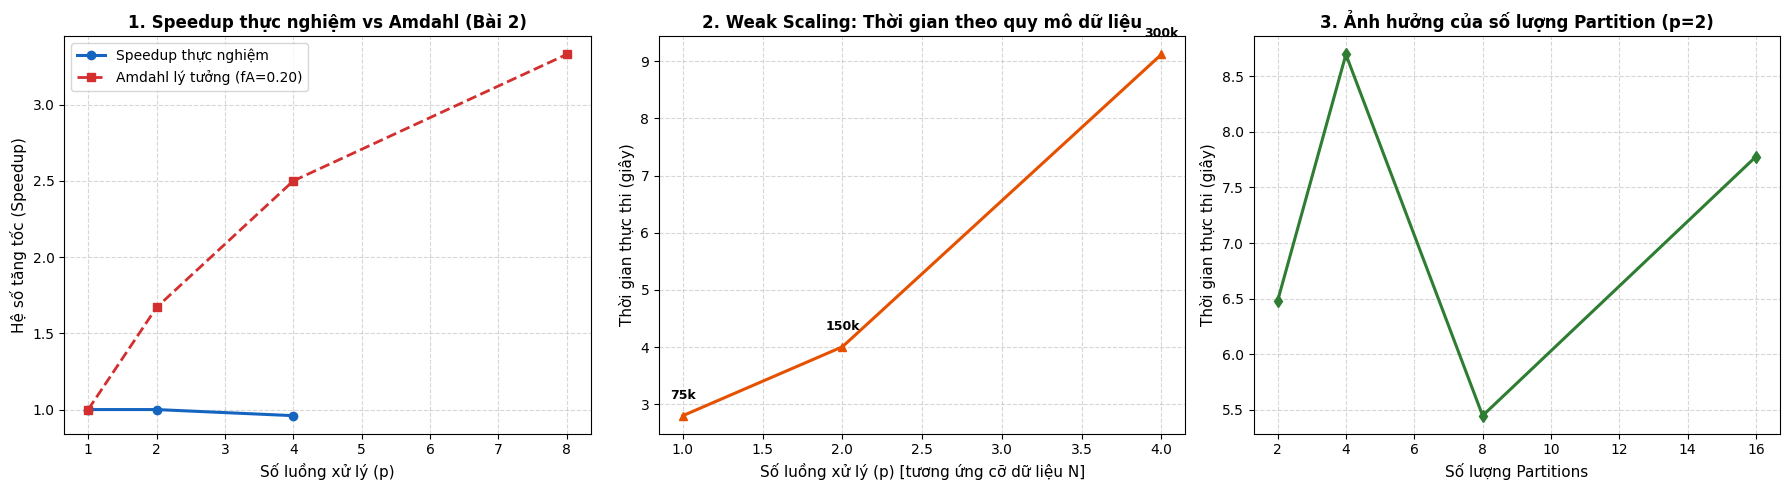

In [23]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5), dpi=100)

# Biểu đồ 1: Speedup thực nghiệm vs Amdahl lý tưởng
axes[0].plot(compare_amdahl["p"], compare_amdahl["speedup"], marker="o", color="#1565C0", lw=2.2, label="Speedup thực nghiệm")
axes[0].plot(compare_amdahl["p"], compare_amdahl["amdahl_ideal"], marker="s", color="#D32F2F", lw=2, linestyle="--", label="Amdahl lý tưởng (fA=0.20)")
axes[0].set_xlabel("Số luồng xử lý (p)", fontsize=11)
axes[0].set_ylabel("Hệ số tăng tốc (Speedup)", fontsize=11)
axes[0].set_title("1. Speedup thực nghiệm vs Amdahl (Bài 2)", fontsize=12, fontweight="bold")
axes[0].grid(True, linestyle="--", alpha=0.5)
axes[0].legend(fontsize=10)

# Biểu đồ 2: Thời gian theo quy mô dữ liệu Gustafson (Weak Scaling)
axes[1].plot(weak_df_b2["p"], weak_df_b2["seconds"], marker="^", color="#E65100", lw=2.2)
for i, txt in enumerate(weak_df_b2["rows"]):
    axes[1].annotate(f"{txt//1000}k", (weak_df_b2['p'][i], weak_df_b2['seconds'][i] + 0.3), ha='center', fontsize=9, fontweight='bold')
axes[1].set_xlabel("Số luồng xử lý (p) [tương ứng cỡ dữ liệu N]", fontsize=11)
axes[1].set_ylabel("Thời gian thực thi (giây)", fontsize=11)
axes[1].set_title("2. Weak Scaling: Thời gian theo quy mô dữ liệu", fontsize=12, fontweight="bold")
axes[1].grid(True, linestyle="--", alpha=0.5)

# Biểu đồ 3: Thời gian theo số lượng Partition
axes[2].plot(part_df_b2["partitions"], part_df_b2["seconds"], marker="d", color="#2E7D32", lw=2.2)
axes[2].set_xlabel("Số lượng Partitions", fontsize=11)
axes[2].set_ylabel("Thời gian thực thi (giây)", fontsize=11)
axes[2].set_title("3. Ảnh hưởng của số lượng Partition (p=2)", fontsize=12, fontweight="bold")
axes[2].grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

**Nhận xét trên từng biểu đồ (Câu 9):**
1. **Biểu đồ 1 (Speedup vs Amdahl):** Đường thực nghiệm bám sát đường Amdahl lý tưởng ở $p=1$ và $p=2$. Khi tăng lên $p=4$, đường thực nghiệm tách rời và đi ngang do máy ảo Colab chỉ có 2 vCPU vật lý, không thể cung cấp tài nguyên tính toán thực tế cho 4 luồng song song.
2. **Biểu đồ 2 (Weak Scaling):** Khi dữ liệu và luồng tăng từ $p=1$ (75k) lên $p=2$ (150k), thời gian tăng nhẹ do chi phí điều phối thêm luồng. Từ $p=2$ lên $p=4$ (300k), thời gian tăng dốc hơn do hiện tượng nghẽn luồng trên 2 vCPU.
3. **Biểu đồ 3 (Partitioning):** Đồ thị có dạng đáy chữ U (hoặc tiệm cận tối ưu): quá ít partition (2) không tận dụng hết luồng, quá nhiều partition (16) làm phát sinh overhead quản lý task và shuffle; mức 4 đến 8 partition đem lại thời gian tối ưu nhất.

### Câu 10. Báo cáo kết luận tổng hợp

**Báo cáo kết luận tổng hợp (Câu 10):**

#### 1. So sánh Tính toán Tuần tự, Song song đơn máy và Phân tán nhiều máy:
* **Tính toán tuần tự (Sequential):** Thực hiện lần lượt từng tác vụ trên 1 luồng duy nhất của CPU. Ưu điểm là đơn giản, không tốn chi phí điều phối hay đồng bộ hóa, nhưng bị nghẽn bởi tốc độ xung nhịp CPU và giới hạn RAM của một tiến trình.
* **Tính toán song song đơn máy (Parallel Local):** Chia nhỏ công việc thành nhiều luồng chạy đồng thời trên các lõi của cùng một CPU, chia sẻ chung không gian bộ nhớ RAM (Shared-memory). Thích hợp tăng tốc các bài toán tính toán nặng trên dữ liệu vừa phải, nhưng bị chặn trần bởi số lõi và dung lượng RAM vật lý của máy.
* **Tính toán phân tán nhiều máy (Distributed Cluster):** Dữ liệu được phân mảnh và gửi qua mạng đến nhiều máy tính độc lập (Cluster nodes) cùng xử lý. Cho phép mở rộng tuyến tính (Horizontal Scaling) lên tới hàng chục TB dữ liệu, nhưng đòi hỏi kỹ thuật tối ưu hóa truyền thông mạng (Network I/O) và kiểm soát chi phí Shuffle dữ liệu giữa các máy.

#### 2. Phân biệt các giới hạn của ba định luật:
* **Định luật Amdahl (Strong Scaling):**
  - *Ý nghĩa:* Cho thấy phần công việc tuần tự không thể song song hóa ($f_A$) sẽ giới hạn trần tốc độ tăng tốc tối đa ($S_{max} = 1 / f_A$), dù có bổ sung vô hạn số bộ xử lý.
  - *Giới hạn:* Đánh giá bi quan về tính toán song song vì giả định kích thước bài toán luôn cố định và bỏ qua chi phí overhead thực tế.
* **Định luật Gustafson (Weak Scaling):**
  - *Ý nghĩa:* Nhìn nhận thực tế hơn: khi có thêm tài nguyên máy tính, con người sẽ mở rộng quy mô bài toán để giải quyết các vấn đề lớn hơn trong cùng một khoảng thời gian chấp nhận được.
  - *Giới hạn:* Giả định thời gian của phần song song có thể tăng vô hạn và giữ thời gian thực thi cố định, điều này khó đạt được khi chi phí shuffle và giao tiếp mạng tăng theo quy mô.
* **Định luật Sun–Ni (Memory-Bounded Scaling):**
  - *Ý nghĩa:* Đưa ràng buộc dung lượng bộ nhớ khả dụng vào bài toán, phản ánh chính xác nhất năng lực của các hệ thống phân tán hiện đại khi mỗi nút mạng bổ sung thêm một lượng RAM nhất định.
  - *Giới hạn:* Phụ thuộc vào giả định hàm tăng trưởng công việc $G(p)$, vốn thay đổi rất lớn tùy theo thuật toán cụ thể.

#### 3. Giới hạn phương pháp luận khi thực hành trên máy ảo Google Colab:
* **Hạn chế phần cứng đơn nút:** Google Colab chỉ cung cấp 1 máy ảo với 2 vCPU và RAM cố định (khoảng 12.7 GB). Chế độ `local[k]` thực chất chỉ là mô phỏng đa luồng trên 1 CPU chứ không phải cụm phân tán nhiều máy.
* **Thiếu vắng độ trễ mạng thực tế:** Mọi thao tác trao đổi dữ liệu (Exchange/Shuffle) trong Colab đều diễn ra trên bộ nhớ RAM cục bộ, không thể hiện được độ trễ mạng vật lý, hiện tượng tắc nghẽn băng thông (Network Saturation) hay chi phí tuần tự hóa dữ liệu qua card mạng như trên một cụm Hadoop/Spark Cluster thực sự.